# Workshop #3 — Reading the Gold layer
The Gold DAG (`gold_processing_dag`, PySpark) writes two long-format Parquet files. This notebook reads the latest of
each with pandas and previews what the Workshop #4 dashboard will show.

In [1]:
import json, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SILVER = ROOT / "datalake_silver"
GOLD = ROOT / "datalake_gold"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
gov_file = sorted(GOLD.glob("governance_*.parquet"))[-1]
story_file = sorted(GOLD.glob("storytelling_*.parquet"))[-1]
gov, story = pd.read_parquet(gov_file), pd.read_parquet(story_file)
print(gov_file.name, gov.shape, "|", story_file.name, story.shape)
gov.dtypes

governance_20261121_175940.parquet (138, 8) | storytelling_20261121_175940.parquet (1789, 11)


kpi                           str
topic                         str
field                         str
period                        str
value                     float64
unit                          str
detail                        str
computed_at_utc    datetime64[ns]
dtype: object

## Governance KPIs

In [3]:
gov[gov.kpi != "null_rate"].drop(columns="computed_at_utc")

,kpi,topic,field,period,value,unit,detail
0,volume_rows,rainfall,NaN,NaN,10800.000000,rows,NaN
1,volume_bronze_files,rainfall,NaN,NaN,9.000000,files,NaN
2,volume_rows_per_day,rainfall,NaN,2026-11-21,10800.000000,rows,NaN
19,duplicate_rate_before,rainfall,station_name+timestamp,NaN,88.888889,%,9600 repeated keys of 10800
20,duplicate_rate_after,rainfall,station_name+timestamp,NaN,0.000000,%,Gold keeps one row per key (most recent foreca...
21,schema_compliance_rate,rainfall,NaN,NaN,100.000000,%,"required: station_name, timestamp, latitude, l..."
22,outlier_rate,rainfall,precip_outlier_iqr,NaN,3.888889,%,NaN
23,outlier_rate,rainfall,precip_outlier_zscore,NaN,1.250000,%,NaN
24,flag_rate,rainfall,soil_moisture_imputed,NaN,0.000000,%,NaN
25,freshness_hours,rainfall,NaN,NaN,0.588889,hours,last processed 2026-11-21 17:24 UTC


In [4]:
gov[(gov.kpi == "null_rate") & (gov.value > 0)].sort_values("value", ascending=False)[["topic", "field", "value", "detail"]]

,topic,field,value,detail
55,landslides,event_time,100.000000,109 of 109
66,landslides,storm_name,100.000000,109 of 109
68,landslides,notes,98.165138,107 of 109
67,landslides,photo_link,87.155963,95 of 109
65,landslides,injury_count,74.311927,81 of 109
71,landslides,country_name,7.339450,8 of 109
69,landslides,event_import_source,7.339450,8 of 109
70,landslides,event_import_id,7.339450,8 of 109
72,landslides,country_code,7.339450,8 of 109
74,landslides,admin_division_population,7.339450,8 of 109


## Storytelling: risk per monitoring point (US-01, US-02, US-03)

In [5]:
print(story[story.section == "narrative"].text.iloc[0])
risk = story[story.section == "station_risk"].pivot_table(index="entity", columns="metric", values="value")
risk["level"] = story[(story.section == "station_risk") & (story.metric == "score")].set_index("entity").text
risk.sort_values("score", ascending=False).round(2)

Latest forecast (2026-11-21 12:23 UTC): 10 monitoring points; highest risk at Pasto (score 0.51, MEDIUM). Rain relative to history is highest at Pasto: 107 mm in 5 days = 99% of the November 5-day P90 (109 mm).


metric,events_30km,fatalities_30km,h_lhasa,max_hourly_mm,p24h_mm,p50_ant_hist_mm,p90_ant_hist_mm,p_ant_mm,ratio_vs_p90,score,level
entity,,,,,,,,,,,
Pasto,3.0,14.0,0.16,6.3,16.1,67.4,108.8,107.2,0.99,0.51,MEDIUM
Medellin,9.0,157.0,0.11,7.3,11.0,36.7,61.3,31.3,0.51,0.35,LOW
Bogota,4.0,13.0,0.01,6.7,3.2,17.7,43.1,19.7,0.46,0.26,LOW
Manizales,7.0,94.0,0.03,3.3,4.3,57.5,96.3,31.9,0.33,0.24,LOW
Ibague,0.0,NaN,0.02,3.3,7.5,56.8,99.9,47.1,0.47,0.20,LOW
Cali,4.0,6.0,0.07,3.2,3.4,53.5,105.7,26.4,0.25,0.20,LOW
Bucaramanga,5.0,9.0,0.01,2.3,2.9,49.6,111.9,19.7,0.18,0.18,LOW
Pereira,2.0,13.0,0.01,2.6,1.4,54.8,93.4,31.7,0.34,0.17,LOW
Mocoa,1.0,329.0,0.02,3.6,4.7,46.0,107.8,22.7,0.21,0.12,LOW


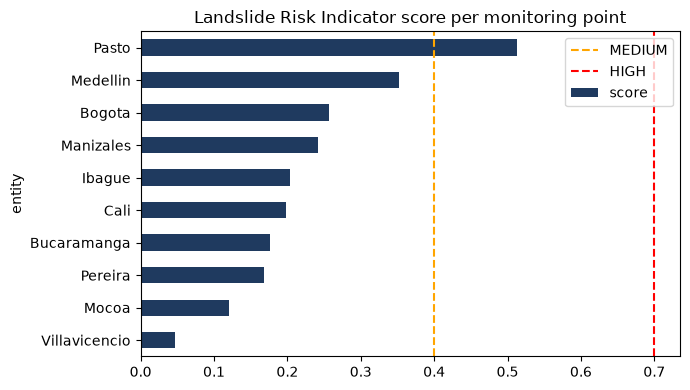

In [6]:
ax = risk.sort_values("score").score.plot.barh(figsize=(7, 4), color="#1f3a5f")
ax.axvline(0.40, ls="--", color="orange", label="MEDIUM"); ax.axvline(0.70, ls="--", color="red", label="HIGH")
ax.set_title("Landslide Risk Indicator score per monitoring point"); ax.legend(); plt.tight_layout(); plt.show()

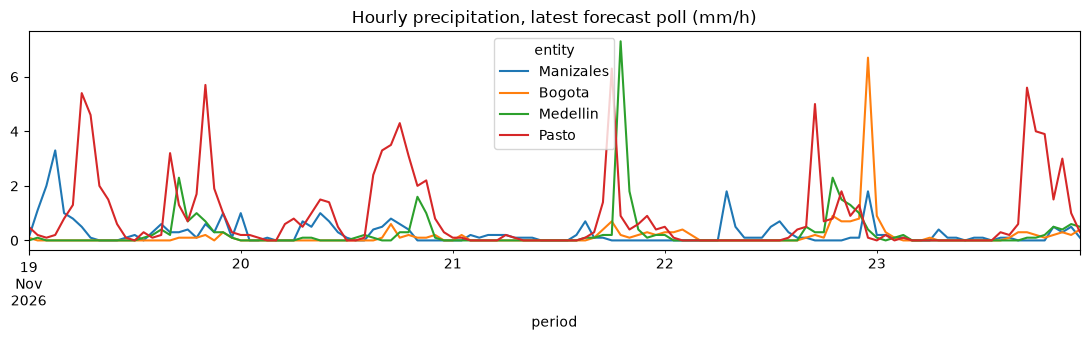

In [7]:
hourly = story[story.section == "hourly_rainfall"].pivot_table(index="period", columns="entity", values="value")
hourly.index = pd.to_datetime(hourly.index)
hourly[risk.sort_values("score").index[-4:]].plot(figsize=(11, 3.5), title="Hourly precipitation, latest forecast poll (mm/h)")
plt.tight_layout(); plt.show()

## Storytelling: historical landslides and text (US-04)

In [8]:
for sec in ["landslides_by_year", "landslides_by_trigger", "landslides_by_size"]:
    print(story[(story.section == sec)].pivot_table(index="entity", columns="metric", values="value").fillna(0).astype(int).T.to_string(), "\n")

entity      2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017
metric                                                                      
events         3     9     2    23    39     5     2     8     4     9     5
fatalities    37    67     6   143   168    22    11    24    92    53   348 

entity      construction  continuous_rain  downpour  mining  rain  unknown
metric                                                                    
events                 1                6        80       1    18        3
fatalities             5               36       764       5   153        8 

entity      catastrophic  large  medium  small  unknown  very_large
metric                                                             
events                 1     30      66      5        3           4
fatalities           329    323     152      2        2         163 



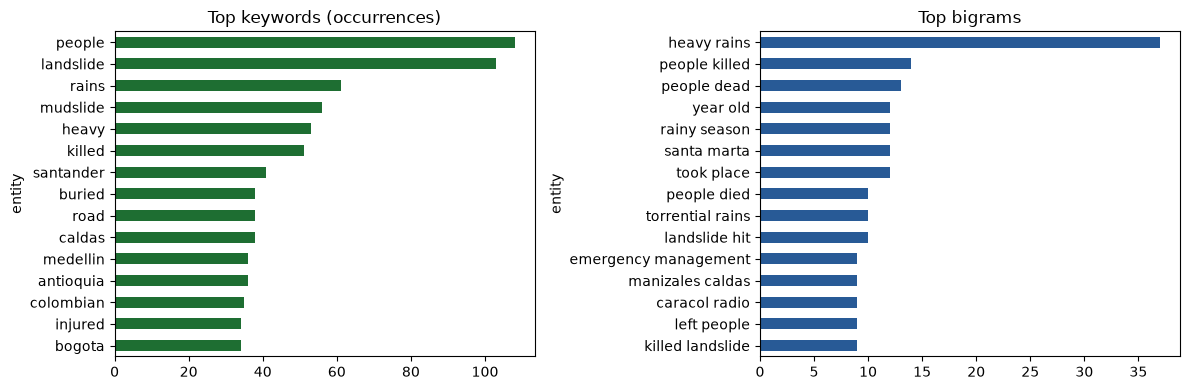

metric,avg_fatalities,freq
entity,,
people,12.3,108.0
landslide,13.5,103.0
rains,5.3,61.0
mudslide,4.9,56.0
heavy,18.2,53.0
killed,10.5,51.0
santander,3.2,41.0
caldas,9.8,38.0
buried,9.3,38.0


In [9]:
kw = story[story.section == "top_keywords"].pivot_table(index="entity", columns="metric", values="value").sort_values("freq", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
kw.freq.head(15).sort_values().plot.barh(ax=ax[0], color="#1e6e32", title="Top keywords (occurrences)")
story[story.section == "top_bigrams"].set_index("entity").value.head(15).sort_values().plot.barh(ax=ax[1], color="#285a96", title="Top bigrams")
plt.tight_layout(); plt.show()
kw.head(15).round(1)